In [ ]:
from google .colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Importing the Required Librarys
# Read data set from Drive and name it as diab then print the data
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import load_model
diab=pd.read_csv("/content/drive/MyDrive/assignment/diabetes.csv")
diab.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
#print the rows and column
diab.shape

(768, 9)

In [ ]:
#print the data information with their Data Types
diab.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
#Print the nomber of columns in data set
for i in diab.columns:
  print (i)

Pregnancies
Glucose
BloodPressure
SkinThickness
Insulin
BMI
DiabetesPedigreeFunction
Age
Outcome


In [ ]:
# print The detailed informaion of data set
diab.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [ ]:
diab.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
#print the unique values on the data set columns
for i in diab.columns:
  print("\n",i,":")
  print("\n",diab[i].unique())



 Pregnancies :

 [ 6  1  8  0  5  3 10  2  4  7  9 11 13 15 17 12 14]

 Glucose :

 [148  85 183  89 137 116  78 115 197 125 110 168 139 189 166 100 118 107
 103 126  99 196 119 143 147  97 145 117 109 158  88  92 122 138 102  90
 111 180 133 106 171 159 146  71 105 101 176 150  73 187  84  44 141 114
  95 129  79   0  62 131 112 113  74  83 136  80 123  81 134 142 144  93
 163 151  96 155  76 160 124 162 132 120 173 170 128 108 154  57 156 153
 188 152 104  87  75 179 130 194 181 135 184 140 177 164  91 165  86 193
 191 161 167  77 182 157 178  61  98 127  82  72 172  94 175 195  68 186
 198 121  67 174 199  56 169 149  65 190]

 BloodPressure :

 [ 72  66  64  40  74  50   0  70  96  92  80  60  84  30  88  90  94  76
  82  75  58  78  68 110  56  62  85  86  48  44  65 108  55 122  54  52
  98 104  95  46 102 100  61  24  38 106 114]

 SkinThickness :

 [35 29  0 23 32 45 19 47 38 30 41 33 26 15 36 11 31 37 42 25 18 24 39 27
 21 34 10 60 13 20 22 28 54 40 51 56 14 17 50 44 12 46 16

In [ ]:
# print the count of unique values on diab columns
for i in diab.columns :
  print("\n",i,":",diab[i].unique().sum())


 Pregnancies : 137

 Glucose : 17518

 BloodPressure : 3422

 SkinThickness : 1680

 Insulin : 35160

 BMI : 8359.0

 DiabetesPedigreeFunction : 276.44

 Age : 2428

 Outcome : 1


Finding the any outlayer value will inside of the particullar columns on the data set and find the sum of count


In [ ]:
#Print the particular columns unique value for they find contain any outlayer of data value
diab['Pregnancies'].unique()

array([ 6,  1,  8,  0,  5,  3, 10,  2,  4,  7,  9, 11, 13, 15, 17, 12, 14])

In [ ]:
# Check if 'Pregnancies' column contains 0 and count the occurrences
diabe = (diab['Pregnancies'].isin([0])).sum()
diabe


111

The pregnancies may be 0 is no a outlayer   

In [ ]:
# display the unique values of the Glucose column
diab['Glucose'].unique()


array([148,  85, 183,  89, 137, 116,  78, 115, 197, 125, 110, 168, 139,
       189, 166, 100, 118, 107, 103, 126,  99, 196, 119, 143, 147,  97,
       145, 117, 109, 158,  88,  92, 122, 138, 102,  90, 111, 180, 133,
       106, 171, 159, 146,  71, 105, 101, 176, 150,  73, 187,  84,  44,
       141, 114,  95, 129,  79,   0,  62, 131, 112, 113,  74,  83, 136,
        80, 123,  81, 134, 142, 144,  93, 163, 151,  96, 155,  76, 160,
       124, 162, 132, 120, 173, 170, 128, 108, 154,  57, 156, 153, 188,
       152, 104,  87,  75, 179, 130, 194, 181, 135, 184, 140, 177, 164,
        91, 165,  86, 193, 191, 161, 167,  77, 182, 157, 178,  61,  98,
       127,  82,  72, 172,  94, 175, 195,  68, 186, 198, 121,  67, 174,
       199,  56, 169, 149,  65, 190])

In [ ]:
# print how many rows of Glucose column contanin 0
diabe=(diab['Glucose'].isin([0])).sum()
#diabe1=diabe.isnull().sum()
diabe

5

The above Glucose contain 5 outlier values  


In [ ]:
#print the unique values  on het BloodPreasure column
diabe=diab['BloodPressure'].unique()
diabe

array([ 72,  66,  64,  40,  74,  50,   0,  70,  96,  92,  80,  60,  84,
        30,  88,  90,  94,  76,  82,  75,  58,  78,  68, 110,  56,  62,
        85,  86,  48,  44,  65, 108,  55, 122,  54,  52,  98, 104,  95,
        46, 102, 100,  61,  24,  38, 106, 114])

In [ ]:
# display the content of BloodPreasure couluns contain 0
diabe=(diab['BloodPressure'].isin([0]).sum())
#diabe1=diabe.isnull().sum()
diabe

35

In [ ]:
#display the unique values of SkinThickness column
diabe=diab['SkinThickness'].unique()
diabe

array([35, 29,  0, 23, 32, 45, 19, 47, 38, 30, 41, 33, 26, 15, 36, 11, 31,
       37, 42, 25, 18, 24, 39, 27, 21, 34, 10, 60, 13, 20, 22, 28, 54, 40,
       51, 56, 14, 17, 50, 44, 12, 46, 16,  7, 52, 43, 48,  8, 49, 63, 99])

In [ ]:
#diaplay the count of how many rows are contain value 0
diabe=(diab['SkinThickness'].isin([0]).sum())
diabe

227

In [ ]:
#display the unique values of Insulin column
diabe=diab['Insulin'].unique()
diabe

array([  0,  94, 168,  88, 543, 846, 175, 230,  83,  96, 235, 146, 115,
       140, 110, 245,  54, 192, 207,  70, 240,  82,  36,  23, 300, 342,
       304, 142, 128,  38, 100,  90, 270,  71, 125, 176,  48,  64, 228,
        76, 220,  40, 152,  18, 135, 495,  37,  51,  99, 145, 225,  49,
        50,  92, 325,  63, 284, 119, 204, 155, 485,  53, 114, 105, 285,
       156,  78, 130,  55,  58, 160, 210, 318,  44, 190, 280,  87, 271,
       129, 120, 478,  56,  32, 744, 370,  45, 194, 680, 402, 258, 375,
       150,  67,  57, 116, 278, 122, 545,  75,  74, 182, 360, 215, 184,
        42, 132, 148, 180, 205,  85, 231,  29,  68,  52, 255, 171,  73,
       108,  43, 167, 249, 293,  66, 465,  89, 158,  84,  72,  59,  81,
       196, 415, 275, 165, 579, 310,  61, 474, 170, 277,  60,  14,  95,
       237, 191, 328, 250, 480, 265, 193,  79,  86, 326, 188, 106,  65,
       166, 274,  77, 126, 330, 600, 185,  25,  41, 272, 321, 144,  15,
       183,  91,  46, 440, 159, 540, 200, 335, 387,  22, 291, 39

In [ ]:
#display the count of how many rows insulin column contain value 0
diabe=(diab["Insulin"].isin([0]).sum())
diabe


374

In [ ]:
#display the unique values of BMI
diabe=diab['BMI'].unique()
diabe

array([33.6, 26.6, 23.3, 28.1, 43.1, 25.6, 31. , 35.3, 30.5,  0. , 37.6,
       38. , 27.1, 30.1, 25.8, 30. , 45.8, 29.6, 43.3, 34.6, 39.3, 35.4,
       39.8, 29. , 36.6, 31.1, 39.4, 23.2, 22.2, 34.1, 36. , 31.6, 24.8,
       19.9, 27.6, 24. , 33.2, 32.9, 38.2, 37.1, 34. , 40.2, 22.7, 45.4,
       27.4, 42. , 29.7, 28. , 39.1, 19.4, 24.2, 24.4, 33.7, 34.7, 23. ,
       37.7, 46.8, 40.5, 41.5, 25. , 25.4, 32.8, 32.5, 42.7, 19.6, 28.9,
       28.6, 43.4, 35.1, 32. , 24.7, 32.6, 43.2, 22.4, 29.3, 24.6, 48.8,
       32.4, 38.5, 26.5, 19.1, 46.7, 23.8, 33.9, 20.4, 28.7, 49.7, 39. ,
       26.1, 22.5, 39.6, 29.5, 34.3, 37.4, 33.3, 31.2, 28.2, 53.2, 34.2,
       26.8, 55. , 42.9, 34.5, 27.9, 38.3, 21.1, 33.8, 30.8, 36.9, 39.5,
       27.3, 21.9, 40.6, 47.9, 50. , 25.2, 40.9, 37.2, 44.2, 29.9, 31.9,
       28.4, 43.5, 32.7, 67.1, 45. , 34.9, 27.7, 35.9, 22.6, 33.1, 30.4,
       52.3, 24.3, 22.9, 34.8, 30.9, 40.1, 23.9, 37.5, 35.5, 42.8, 42.6,
       41.8, 35.8, 37.8, 28.8, 23.6, 35.7, 36.7, 45

In [ ]:
#display the count of how many rows of the BMI column contain value of 0
diabe=(diab["BMI"].isin([0]).sum())
diabe

11

In [ ]:
#diasplay unique values of DiabetesPegreeFunction
diabe=diab['DiabetesPedigreeFunction'].unique()
diabe

array([0.627, 0.351, 0.672, 0.167, 2.288, 0.201, 0.248, 0.134, 0.158,
       0.232, 0.191, 0.537, 1.441, 0.398, 0.587, 0.484, 0.551, 0.254,
       0.183, 0.529, 0.704, 0.388, 0.451, 0.263, 0.205, 0.257, 0.487,
       0.245, 0.337, 0.546, 0.851, 0.267, 0.188, 0.512, 0.966, 0.42 ,
       0.665, 0.503, 1.39 , 0.271, 0.696, 0.235, 0.721, 0.294, 1.893,
       0.564, 0.586, 0.344, 0.305, 0.491, 0.526, 0.342, 0.467, 0.718,
       0.962, 1.781, 0.173, 0.304, 0.27 , 0.699, 0.258, 0.203, 0.855,
       0.845, 0.334, 0.189, 0.867, 0.411, 0.583, 0.231, 0.396, 0.14 ,
       0.391, 0.37 , 0.307, 0.102, 0.767, 0.237, 0.227, 0.698, 0.178,
       0.324, 0.153, 0.165, 0.443, 0.261, 0.277, 0.761, 0.255, 0.13 ,
       0.323, 0.356, 0.325, 1.222, 0.179, 0.262, 0.283, 0.93 , 0.801,
       0.207, 0.287, 0.336, 0.247, 0.199, 0.543, 0.192, 0.588, 0.539,
       0.22 , 0.654, 0.223, 0.759, 0.26 , 0.404, 0.186, 0.278, 0.496,
       0.452, 0.403, 0.741, 0.361, 1.114, 0.457, 0.647, 0.088, 0.597,
       0.532, 0.703,

In [ ]:
#display how many rows of DiabetesPedigreeFunction column contain 0
diabe=(diab['DiabetesPedigreeFunction'].isin([0]).sum())
diabe

0

In [ ]:
#print the unique values of Age
diabe=diab['Age'].unique()
diabe

array([50, 31, 32, 21, 33, 30, 26, 29, 53, 54, 34, 57, 59, 51, 27, 41, 43,
       22, 38, 60, 28, 45, 35, 46, 56, 37, 48, 40, 25, 24, 58, 42, 44, 39,
       36, 23, 61, 69, 62, 55, 65, 47, 52, 66, 49, 63, 67, 72, 81, 64, 70,
       68])

In [ ]:
#display how many rows od Age colunm contain the value of 0
diabe=(diab['Age'].isin([0]).sum())
diabe

0

In [ ]:
#Replacing the outlayer value to the np.nan (its help to convert not an number of outlayer values)
diab.Glucose=diab.Glucose.replace(0,np.nan)
diab.BloodPressure=diab.BloodPressure.replace(0,np.nan)
diab.SkinThickness=diab.SkinThickness.replace(0,np.nan)
diab.Insulin=diab.Insulin.replace(0,np.nan)
diab.BMI=diab.BMI.replace(0,np.nan)

In [ ]:
#print the sum of the count after use nan
diab.isnull().sum()

,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
#After replace all the not a number to values to use the functions like mean(),median(),mode()
diab.Glucose=diab.Glucose.fillna(diab.Glucose.mean())
diab.BloodPressure=diab.BloodPressure.fillna(diab.BloodPressure.mean())
diab.SkinThickness=diab.SkinThickness.fillna(diab.SkinThickness.mean())
diab.Insulin=diab.Insulin.fillna(diab.Insulin.mean())
diab.BMI=diab.BMI.fillna(diab.BMI.mean())

In [ ]:
#Display the dataset which contain any outlayer on data after replacing the mean() and median().mode()
diab.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
#print the types of data set with their column name
diab.dtypes

,0
Pregnancies,int64
Glucose,float64
BloodPressure,float64
SkinThickness,float64
Insulin,float64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


In [ ]:
#shows how many number of rows and columns contin data set
diab.shape

(768, 9)

In [ ]:
#convert the data set value to numpy array values for fast computational process
diabe=diab.to_numpy()
print(diabe)

[[  6.    148.     72.    ...   0.627  50.      1.   ]
 [  1.     85.     66.    ...   0.351  31.      0.   ]
 [  8.    183.     64.    ...   0.672  32.      1.   ]
 ...
 [  5.    121.     72.    ...   0.245  30.      0.   ]
 [  1.    126.     60.    ...   0.349  47.      1.   ]
 [  1.     93.     70.    ...   0.315  23.      0.   ]]


In [ ]:
#extract the feature valriable values from diab dataset and name to x using the concept slicing
x=diabe[:,0:8]
df=pd.DataFrame(x)
df.head()

,0,1,2,3,4,5,6,7
0,6.0,148.0,72.0,35.00000,155.548223,33.6,0.627,50.0
1,1.0,85.0,66.0,29.00000,155.548223,26.6,0.351,31.0
2,8.0,183.0,64.0,29.15342,155.548223,23.3,0.672,32.0
3,1.0,89.0,66.0,23.00000,94.000000,28.1,0.167,21.0
4,0.0,137.0,40.0,35.00000,168.000000,43.1,2.288,33.0


In [ ]:
#extract the target variable values form diab dataset and name it to  y and give name too...
y=diabe[:,8]
y

array([1., 0., 1., 0., 1., 0., 1., 0., 1., 1., 0., 1., 0., 1., 1., 1., 1.,
       1., 0., 1., 0., 0., 1., 1., 1., 1., 1., 0., 0., 0., 0., 1., 0., 0.,
       0., 0., 0., 1., 1., 1., 0., 0., 0., 1., 0., 1., 0., 0., 1., 0., 0.,
       0., 0., 1., 0., 0., 1., 0., 0., 0., 0., 1., 0., 0., 1., 0., 1., 0.,
       0., 0., 1., 0., 1., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 1.,
       0., 0., 0., 1., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 1., 1., 0.,
       0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 0., 0., 1., 1., 1., 0., 0.,
       0., 1., 0., 0., 0., 1., 1., 0., 0., 1., 1., 1., 1., 1., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 1.,
       0., 1., 1., 0., 0., 0., 1., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0.,
       1., 1., 0., 0., 0., 1., 0., 1., 0., 1., 0., 0., 0., 0., 0., 1., 1.,
       1., 1., 1., 0., 0., 1., 1., 0., 1., 0., 1., 1., 1., 0., 0., 0., 0.,
       0., 0., 1., 1., 0., 1., 0., 0., 0., 1., 1., 1., 1., 0., 1., 1., 1.,
       1., 0., 0., 0., 0.

In [ ]:
scalar=StandardScaler()
x=scalar.fit_transform(x)
x[0]

array([ 6.39947260e-01,  8.65108070e-01, -3.35182392e-02,  6.65502121e-01,
       -3.34507888e-16,  1.66291742e-01,  4.68491977e-01,  1.42599540e+00])

In [ ]:
x[1]

array([-8.44885053e-01, -1.20616153e+00, -5.29859033e-01, -1.74633816e-02,
       -3.34507888e-16, -8.52531177e-01, -3.65060778e-01, -1.90671905e-01])

In [ ]:
#spliting the data set to train and test and splict using the concept x_train,x+test,ytrain
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=30)
print("The Data Range After Spliting:\n")
print(x_train.shape,y_train.shape,x_test.shape,y_test.shape)

The Data Range After Spliting:

(614, 8) (614,) (154, 8) (154,)


In [ ]:
#print the x_train and y_train data after spliting the train_test_split
x_train,y_train

(array([[-0.25095213, -1.99521662,  0.79371642, ...,  0.28272865,
         -0.69123359,  1.08564439],
        [-1.14185152, -0.54861563,  0.95916335, ..., -0.66332121,
          0.81278551,  2.44704844],
        [ 1.23388019, -0.54861563,  2.2827388 , ...,  1.57808922,
         -0.70331407,  1.00055664],
        ...,
        [-0.25095213,  0.20756216,  0.46282255, ..., -1.6530349 ,
         -0.61573063,  1.85143417],
        [-0.54791859, -0.15408808,  1.45550414, ..., -1.05629576,
         -0.47982529, -1.04154944],
        [-0.54791859, -0.91026588, -0.3644121 , ..., -0.93985886,
          0.26916414, -1.04154944]]),
 array([0., 1., 1., 0., 1., 0., 0., 0., 0., 0., 1., 0., 0., 0., 1., 0., 0.,
        1., 1., 0., 1., 0., 0., 0., 0., 1., 1., 0., 0., 0., 1., 0., 0., 0.,
        0., 0., 0., 1., 0., 0., 1., 1., 0., 1., 0., 0., 0., 1., 1., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 1., 0., 0., 0.,
        1., 0., 1., 1., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 1

In [ ]:
#print the x_test ,y_test data after spliting the train_test_split data
x_test,y_test
x

array([[ 0.63994726,  0.86510807, -0.03351824, ...,  0.16629174,
         0.46849198,  1.4259954 ],
       [-0.84488505, -1.20616153, -0.52985903, ..., -0.85253118,
        -0.36506078, -0.19067191],
       [ 1.23388019,  2.0158134 , -0.69530596, ..., -1.33283341,
         0.60439732, -0.10558415],
       ...,
       [ 0.3429808 , -0.0225789 , -0.03351824, ..., -0.91074963,
        -0.68519336, -0.27575966],
       [-0.84488505,  0.14180757, -1.02619983, ..., -0.34311972,
        -0.37110101,  1.17073215],
       [-0.84488505, -0.94314317, -0.19896517, ..., -0.29945588,
        -0.47378505, -0.87137393]])

Develop a Nura Network of the data

In [ ]:
#import keras from tensorflow library
from tensorflow import keras
#define the class they are represented in target variable or prediction
#in the presiction contain binary class like 0 or 1 so we give the value of 1for number of class
no_of_class=1
#Sequential model is used give the one layer output to next layer input / It is important for creating Nural Network Problem
diab=tf.keras.models.Sequential()
#then add the how many layers of Nuron on the hidden layer and name it,then use the activation function.in the place use "relu"
diab.add(keras.layers.Dense(128,input_shape=(8,),name="Hidden-Layer-1",activation="relu"))
diab.add(keras.layers.Dense(128,input_shape=(8,),name="Hidden-layer-2",activation="relu"))# add hidden layer 2 and name it follow......!
diab.add(keras.layers.Dense(128,input_shape=(8,),name="Hidden-Layer-3",activation='relu'))
# add the output layer and use the activation function sigmiod for binary class classification
diab.add(keras.layers.Dense(no_of_class,name="Output-layer",activation='sigmoid'))
#then after completion of input and output use the compile find loss function use "binary_croessentropy" and metrics used to find the accuracy of the model
diab.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
# summary() is used for print the summary of data model
diab.summary()


/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ Hidden-Layer-1 (Dense)               │ (None, 128)                 │           1,152 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Hidden-layer-2 (Dense)               │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Hidden-Layer-3 (Dense)               │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Output-layer (Dense)                 │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 34,305 (134.00 KB)

 Trainable params: 34,305 (134.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
verbose=1 #used for print how many no of times the iteration process will be made
batch_size=45 #size of the data batch data to iterate in single iteration in process
epochs=15 #how many number time will the peocess will print
validation_split=0.2 #split the data to training nd testing data here testing data =20% and training data is 80%
print("\n Training Prograss:\n!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!")
#fit the above data's to the model
out=diab.fit(x_train,y_train,batch_size=batch_size,epochs=epochs,verbose=verbose,validation_split=validation_split)
print("accuracy During Training:\n..........................................")
#finding the accuracy of the model using history
training_accuracy=out.history['accuracy']
print("Training Accuracy",training_accuracy[-1]*100)


 Training Prograss:
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
Epoch 1/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 1.0000 - loss: 6.9427e-04 - val_accuracy: 0.7398 - val_loss: 2.2740
Epoch 2/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss: 6.0996e-04 - val_accuracy: 0.7398 - val_loss: 2.2699
Epoch 3/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 6.4978e-04 - val_accuracy: 0.7398 - val_loss: 2.2800
Epoch 4/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 6.2347e-04 - val_accuracy: 0.7398 - val_loss: 2.2911
Epoch 5/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 5.9260e-04 - val_accuracy: 0.7317 - val_loss: 2.2848
Epoch 6/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss: 6.1175e-04 - val_accuracy: 0.7398 - val_loss: 2.3131
Epoch 7/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 6.3988e-04 - val_accuracy: 0.7317 - val_loss: 2.3017
Epoch 8/15
11/11 ━━━━━━━━━━━━━━━━━━━

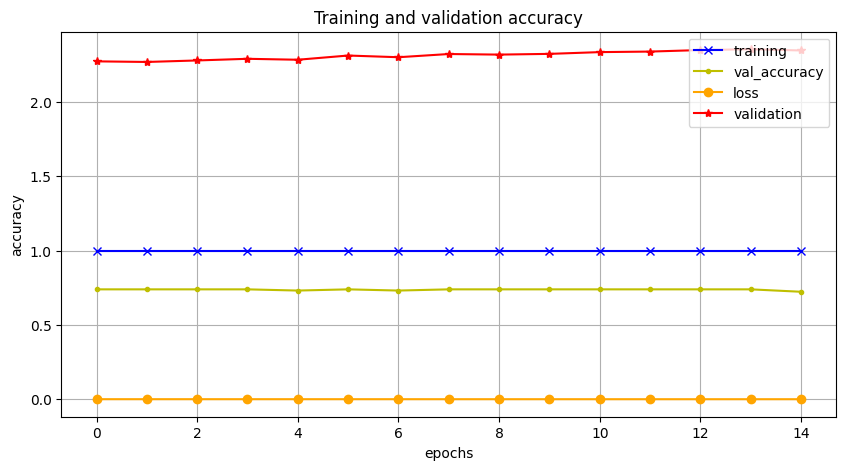

In [ ]:
#dispaly the content in graphical represenattion
import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))#display the size height and weight
#in the place color represents color of the ploting diagram line and marker represents which kind of marker mark the data point,label is used to show the label representation for easily understandable way
plt.plot(out.history['accuracy'],color='b',marker="x",label="training")
plt.plot(out.history['val_accuracy'],color="y",marker='.',label="val_accuracy")
plt.plot(out.history['loss'],color='orange',marker='o',label="loss")
plt.plot(out.history['val_loss'],color="r",marker='*',label='validation')
#title is used to display the title on diagram
plt.title("Training and validation accuracy")
#xlabel,ylabel is used to print content of x asix and y axis
plt.xlabel("epochs")
plt.ylabel("accuracy")
#grid is used to square boxes on image
plt.grid(True)
#legend is used to show the label on the ploting image
plt.legend()
# show is used to display the plot
plt.show()

In [ ]:
"""import plotly.graph_objs as go
import plotly.offline as pyo

# Data for plotting
epochs_range = list(range(len(out.history['accuracy'])))

# Create traces for training accuracy and validation loss
trace1 = go.Scatter(x=epochs_range, y=out.history['accuracy'], mode='lines+markers', name='Training Accuracy', marker=dict(symbol='x'))
trace2 = go.Scatter(x=epochs_range, y=out.history['val_loss'], mode='lines+markers', name='Validation Loss', marker=dict(symbol='star'))
trace3 = go.Scatter(x=epochs_range,y=out.history['val_accuracy'],mode='lines+markers',name='validation accuracy',marker=dict(symbol='star'))

# Create a figure with both traces
data = [trace1, trace2,trace3]
layout = go.Layout(title='Training Accuracy and Validation Loss (Plotly)',
                   xaxis_title='Epoch',
                   yaxis_title='Metric Value')

fig = go.Figure(data=data, layout=layout)

# Display plot
pyo.iplot(fig)
"""


"import plotly.graph_objs as go\nimport plotly.offline as pyo\n\n# Data for plotting\nepochs_range = list(range(len(out.history['accuracy'])))\n\n# Create traces for training accuracy and validation loss\ntrace1 = go.Scatter(x=epochs_range, y=out.history['accuracy'], mode='lines+markers', name='Training Accuracy', marker=dict(symbol='x'))\ntrace2 = go.Scatter(x=epochs_range, y=out.history['val_loss'], mode='lines+markers', name='Validation Loss', marker=dict(symbol='star'))\ntrace3 = go.Scatter(x=epochs_range,y=out.history['val_accuracy'],mode='lines+markers',name='validation accuracy',marker=dict(symbol='star'))\n\n# Create a figure with both traces\ndata = [trace1, trace2,trace3]\nlayout = go.Layout(title='Training Accuracy and Validation Loss (Plotly)',\n                   xaxis_title='Epoch',\n                   yaxis_title='Metric Value')\n\nfig = go.Figure(data=data, layout=layout)\n\n# Display plot\npyo.iplot(fig)\n"

In [ ]:
#import the accuracy_score for predicting accuracy of testing score
from sklearn.metrics import accuracy_score
output=diab.predict(x_test)
output1=np.round(output)
# Calculate accuracy by comparing the predicted labels with y_test
score= accuracy_score(y_test,output1)
print("The Testing Score Is :",score*100)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
The Testing Score Is : 76.62337662337663


In [ ]:
# np.array used to change the scaled value to array of data then predict the putpt and round of for decimal to hole number then print it
input_sample = np.array([[6.39947260e-01,  8.65108070e-01, -3.35182392e-02,  6.65502121e-01,-1.30058043e-17,  1.66291742e-01,  4.68491977e-01,  1.42599540e+00]])
out = diab.predict(input_sample)
out1=np.round(out)
print(out1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
[[1.]]


In [ ]:
ans=diab.predict(np.array([[6	,148	,72	,35	,0,	33.6,	0.627,	50]]))
ans1=np.round(ans)
ans1

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


array([[1.]], dtype=float32)

In [ ]:
# sav the model use .save within the try block  any error will occure the through a error to user
try:
  diab.save("DIABETEC.h5")
  print("model saved successfully")
except OSError as e:
  print("error saving model:{e}")

model saved successfully


In [ ]:
#diab.save("diabetec.h5")

In [ ]:
#reload the model using keras library.models  then print the summary
loadmodel=keras.models.load_model("DIABETEC.h5")
loadmodel.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ Hidden-Layer-1 (Dense)               │ (None, 128)                 │           1,152 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Hidden-layer-2 (Dense)               │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Hidden-Layer-3 (Dense)               │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Output-layer (Dense)                 │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 34,307 (134.02 KB)

 Trainable params: 34,305 (134.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [ ]:
prediction=loadmodel.predict(np.array([[-8.44885053e-01, -1.20616153e+00, -5.29859033e-01, -1.74633816e-02,-2.45706275e-17, -8.52531177e-01, -3.65060778e-01, -1.90671905e-01]]))
predict=np.round(prediction)
print("prediction:",predict)
if predict==1:
  print("The Person is Diabetic")
else:
    print("The person is not Affected in Diabetic")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
prediction: [[0.]]
The person is not Affected in Diabetic


In [ ]:
prediction=loadmodel.predict(np.array([[6.39947260e-01,  8.65108070e-01, -3.35182392e-02,  6.65502121e-01,-1.30058043e-17,  1.66291742e-01,  4.68491977e-01,  1.42599540e+00]]))
predict=np.round(prediction)
print("prediction:",predict)
if predict==1:
  print("The Person is Diabetic")
else:
    print("The person is not Affected in Diabetic")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
prediction: [[1.]]
The Person is Diabetic


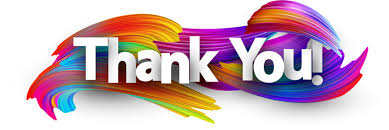